# Phase 2 — Environment, model, training infra, demo

### Multi-Task Visual Counting and Localization in Dense Scenes

1. **Environment setup** — confirm GPU + CUDA, verify 2× RTX 4080 visibility, check packages.
2. **Data conversion (combined → YOLO)** — convert annotations, build train/val/test splits,
   generate `carpk.yaml`.
3. **Build model + loss** — COCO-pretrained YOLO11n with a single 1-class detection head.
4. **Training entry point + multi-GPU (DDP)** support.
5. **Logging** (TensorBoard + plain txt), **hyperparameter logging**, **checkpointing / resume**.
6. **Sanity check** — overfit one batch.
7. **Verification** of DDP correctness, resume and logs.


---
## 0. Setup


In [1]:
import sys
from pathlib import Path

SRC = Path("src/2_phase").resolve()
assert SRC.is_dir(), f"missing module dir: {SRC}"
for p in (SRC, SRC.parent):          # src/2_phase modules + the shared `common` package
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import env_check
import carpk_to_yolo as c2y
import yolo_checks
import model_check
import sanity_overfit
import train_checks
from common import training, run_logging
print("modules loaded from:", SRC)

modules loaded from: /home/mariusz_godlewski/car_recognition/src/2_phase


---
## 1. Environment setup


### 1.1 GPU + CUDA
Confirm `torch.cuda.is_available()` and that both GPUs are visible
(`torch.cuda.device_count() == 2`).


In [2]:
env_check.check_gpus(expected=2)

torch 2.14.1+cu130 | CUDA 13.0 | available True | GPUs 2
GPU 0: NVIDIA GeForce RTX 4080 SUPER | 15.6 GB | compute 8.9
GPU 1: NVIDIA GeForce RTX 4080 SUPER | 15.6 GB | compute 8.9


### 1.2 Confirm both GPUs are free (`nvidia-smi`)


In [3]:
env_check.nvidia_smi();

index, name, memory.used [MiB], memory.total [MiB], utilization.gpu [%]
0, NVIDIA GeForce RTX 4080 SUPER, 4 MiB, 16376 MiB, 0 %
1, NVIDIA GeForce RTX 4080 SUPER, 4 MiB, 16376 MiB, 0 %



---
## 2. Data conversion (combined → YOLO)

We convert the **combined devkit** (`datasets/combined_devkit`, CARPK + PUCPR+).

`carpk_to_yolo.build_dataset`:

- parses the official `train.txt` / `test.txt` splits,
- converts `x1y1x2y2` → normalised `cx cy w h`,
- carves a deterministic **~10% validation** set out of the official *train* split
  (the official **test** images are kept clean),
- links images into `images/{train,val,test}` + writes `labels/{train,val,test}`, and
- emits `carpk.yaml` (`nc: 1`, `names: ['car']`).


In [4]:
OUT_DIR = Path("datasets/yolo")
yaml_path = c2y.build_dataset(Path("datasets/combined_devkit/data"), OUT_DIR, val_fraction=0.1, seed=42)

train:  980 images |  49504 boxes
val  :  109 images |   5711 boxes
test :  484 images |  51420 boxes


### 2.1 Inspect the generated `carpk.yaml`


In [5]:
print(yaml_path.read_text())

path: /home/mariusz_godlewski/car_recognition/datasets/yolo
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: car



### 2.2 Sanity-check the conversion
Verify split sizes, that every label is normalised to `[0, 1]` with class `0`, and that the
images are reachable symlinks.


In [6]:
yolo_checks.summarize_splits(OUT_DIR)
yolo_checks.validate_labels(OUT_DIR)

sample = yolo_checks.pick_sample(OUT_DIR, "train")
yolo_checks.check_symlink(sample)

train: 980 images, 980 labels
val  : 109 images, 109 labels
test : 484 images, 484 labels
out-of-range / wrong-class label lines: 0
image symlink ok: True


### 2.3 Visual check — YOLO boxes on a sample image


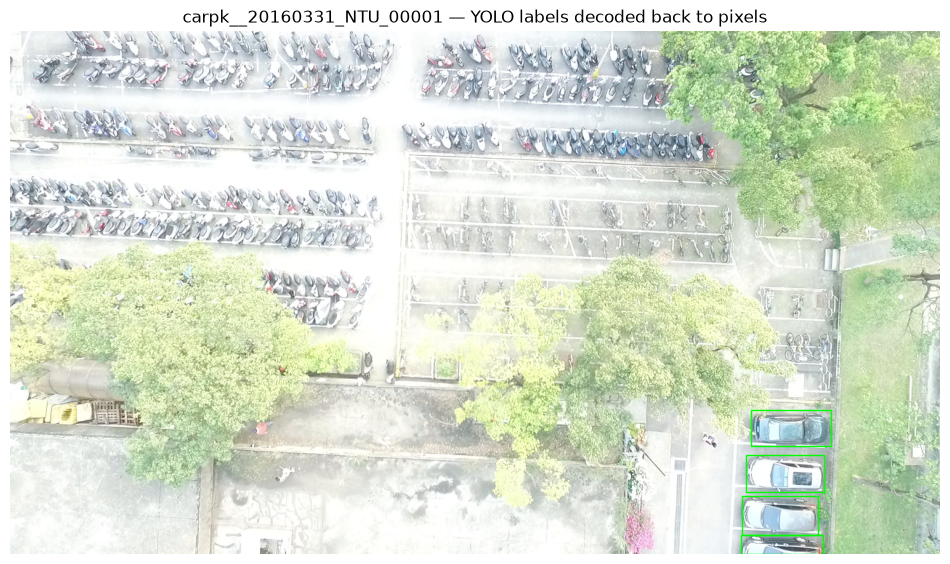

In [7]:
yolo_checks.show_sample(OUT_DIR, sample, split="train");

---
## 3. Build model + loss

The model is **YOLO11n pretrained on COCO**, rebuilt with a **single-class** (`car`) head —
exactly what the Ultralytics trainer does when fine-tuning on `carpk.yaml` (`nc: 1`):

- the architecture is re-created from `yolo11n.yaml` with `nc=1`,
- every tensor whose shape still matches is copied from the COCO checkpoint,
- only the final class-logit convs of the head (80 → 1 output channels) start from scratch.

There is **one detection head only** (`Detect`, 3 strides P3/P4/P5) and no extra counting branch —
the count is simply `len(boxes)` after NMS. The loss is the standard YOLO
`v8DetectionLoss`: **box** (CIoU) + **cls** (BCE) + **DFL** (distribution focal loss), weighted
`7.5 / 0.5 / 1.5`.

In [8]:
model_info = model_check.compare_with_coco()

Overriding model.yaml nc=80 with nc=1


coco: {'n_detect_heads': 1, 'nc': 80, 'outputs_per_anchor': 144, 'strides': [8, 16, 32], 'params_M': 2.62, 'loss': 'v8DetectionLoss', 'loss_gains': {'box': 7.5, 'cls': 0.5, 'dfl': 1.5}}
car : {'n_detect_heads': 1, 'nc': 1, 'outputs_per_anchor': 65, 'strides': [8, 16, 32], 'params_M': 2.6, 'loss': 'v8DetectionLoss', 'loss_gains': {'box': 7.5, 'cls': 0.5, 'dfl': 1.5}}
transferred 493/499 tensors from COCO; re-initialised (class-logit convs):
    model.23.cv3.0.2.weight (1, 80, 1, 1)
    model.23.cv3.0.2.bias (1,)
    model.23.cv3.1.2.weight (1, 80, 1, 1)
    model.23.cv3.1.2.bias (1,)
    model.23.cv3.2.2.weight (1, 80, 1, 1)
    model.23.cv3.2.2.bias (1,)


### 3.1 Loss on a real labelled image
Forward one training image (letterboxed to 1280) through the *fresh* 1-class model, compute the
three loss terms and back-propagate — confirms labels → targets → loss → gradients are wired.
The `cls` loss is high because the new class-logit layer is still random.

In [9]:
sample_lbl = OUT_DIR / "labels" / "train" / f"{sample.stem}.txt"
model_check.loss_on_image(sample, sample_lbl);

Overriding model.yaml nc=80 with nc=1
carpk__20160331_NTU_00001.png: 4 GT cars | {'box_loss': 1.8853377103805542, 'cls_loss': 4.070005416870117, 'dfl_loss': 1.5538634061813354, 'grads_ok': True}


---
## 4. Training entry point + multi-GPU support

Training is started with `training.launch(training.train_args(...))`, which runs
`src/2_phase/train.py` in a subprocess, streams its output here and saves it to `<run>/console.txt`.
This matters for **DDP**: Ultralytics spawns one worker process per GPU via `torch.distributed.run`,
whose output would otherwise never reach the notebook. Phase 3 reuses the same code path:

```python
training.launch(training.train_args(name="full", epochs=100))                     # 2-GPU DDP
training.launch(training.train_args(name="debug", devices=[0], epochs=3, fraction=0.1))  # single GPU
training.launch(resume_from="runs/train/full/weights/last.pt")                     # resume
```

**Multi-GPU (DDP) notes**

- `device=[0,1]` → one process per GPU, gradients all-reduced (averaged) every step.
- `batch` is the **global** batch; each GPU gets `batch // 2` images. Measured at `imgsz=1280`:
  ~5.7 GB/GPU at 8 img/GPU and ~10.9 GB at 16 img/GPU → default `batch_per_gpu=16` (≤ 16 GB).
- Ultralytics does **not** linearly scale `lr0` with the batch: it accumulates gradients up to a
  nominal batch `nbs=64` (`accumulate = round(64 / batch)`) and scales weight decay by
  `batch·accumulate/64`. So 1 GPU and 2 GPUs with the same global batch follow the same
  optimisation — verified in section 7.1.
- Single-GPU fallback: `devices=[0]` (used for the sanity check below).

Default training arguments (from `common/config.py`):

In [11]:
training.train_args()

{'data': '/home/mariusz_godlewski/car_recognition/datasets/yolo/carpk.yaml',
 'epochs': 100,
 'imgsz': 1280,
 'batch': 32,
 'device': [0, 1],
 'project': '/home/mariusz_godlewski/car_recognition/runs/train',
 'name': 'exp',
 'exist_ok': True,
 'seed': 42,
 'deterministic': False,
 'patience': 5}

---
## 5. Logging, hyperparameters, checkpointing

Every run lives in `runs/<project>/<name>/` and contains:

| File | What | Source |
|---|---|---|
| `events.out.tfevents.*` | TensorBoard scalars: train losses, val P/R/mAP, lr per epoch | Ultralytics TB integration (`run_logging.enable_tensorboard()`) |
| `hparams/` | TensorBoard **HParams** (hyperparameters + final metrics) | `run_logging.on_train_end` |
| `train_log.txt` | one greppable line per epoch (losses, metrics, lr, GPU mem, time) + header/summary | `run_logging` callbacks |
| `console.txt` | full console output (all DDP ranks) | `training.launch` |
| `hparams.yaml` | *effective* hparams: lr (after `optimizer=auto`), global/per-GPU batch, accumulate, augmentations | `run_logging.on_train_start` |
| `args.yaml`, `results.csv` | full Ultralytics config, per-epoch metrics table | Ultralytics |
| `weights/last.pt`, `weights/best.pt` | checkpoint saved every epoch / best val fitness (`0.1·mAP50 + 0.9·mAP50-95`) | Ultralytics (`save=True`) |

The custom callbacks are module-level functions in `common/run_logging.py`, so Ultralytics can
pickle them into the DDP workers; they only write from rank 0.
`last.pt` keeps the optimizer / EMA / epoch state while training (→ resumable); at the end both
checkpoints are stripped to inference-only weights.

View the curves with: `tensorboard --logdir runs`

---
## 6. Sanity check — overfit one batch

Four training images (spread over the split, CARPK + PUCPR+) form **one batch** that is both the
train and the val set. Augmentation, weight decay, warmup and gradient accumulation are off
(`nbs = batch`), so each epoch is exactly one optimizer step on the same batch. A correctly wired
pipeline must memorise it: the **box + cls** losses go to ~0 and mAP50 on the batch → ~1.

The **DFL** term cannot reach 0: its targets are soft (each box edge is split between two
neighbouring distance bins), so its minimum is the entropy of that split (~0.75 here).

Runs on a single GPU (`devices=0`), 200 steps (~40 s).

In [15]:
sanity_yaml = sanity_overfit.make_overfit_dataset(n_images=4)
sanity_run = sanity_overfit.run_overfit(sanity_yaml, epochs=200)
sanity_overfit.check_overfit(sanity_run)
sanity_overfit.plot_overfit(sanity_run)

KeyboardInterrupt: 

### 6.1 Sanity-run logs (searchable `.txt`)
`train_log.txt` has one line per step; `console.txt` the full Ultralytics output.

In [13]:
log = run_logging.grep_log(sanity_run)
print("\n".join(l[:160] for l in log[:3] + ["..."] + log[-4:]))
print("\nlogs:", sorted(p.name for p in sanity_run.glob("*.txt")))

# run /home/mariusz_godlewski/car_recognition/runs/sanity/overfit_one_batch started 2026-10-24 15:11:43
# hparams epochs=200 patience=0 batch=4 imgsz=1280 optimizer=AdamW lr0=0.002 lrf=1.0 momentum=0.937 weight_decay=0.0 warmup_epochs=0 cos_lr=False nbs=4 amp=True
epoch 1/200 train/box_loss=1.1356 train/cls_loss=4.4061 train/dfl_loss=1.0788 metrics/precision(B)=0.50893 metrics/recall(B)=0.27273 metrics/mAP50(B)=0.17683 me
...
epoch 199/200 train/box_loss=0.10703 train/cls_loss=0.13106 train/dfl_loss=0.7624 metrics/precision(B)=0.98577 metrics/recall(B)=0.99522 metrics/mAP50(B)=0.9947
epoch 200/200 train/box_loss=0.1079 train/cls_loss=0.12873 train/dfl_loss=0.76276 metrics/precision(B)=0.98305 metrics/recall(B)=0.99522 metrics/mAP50(B)=0.9912
final_best metrics/precision(B)=0.98548 metrics/recall(B)=0.99522 metrics/mAP50(B)=0.995 metrics/mAP50-95(B)=0.97905
# finished 2026-10-24 15:12:35 best_epoch=189 best=/home/mariusz_godlewski/car_recognition/runs/sanity/overfit_one_batch/weights/be

---
## 7. Verifying the training infrastructure

### 7.1 Multi-GPU correctness: 1 GPU vs 2-GPU DDP
Same short schedule (3 epochs on 50% of train), same seed and **same global batch (16)**: once
on GPU 0 alone, once with DDP on both GPUs (8 img/GPU). The loss curves must agree (they differ
only by data-order / numerical noise) and DDP should be faster. The speedup on such a short run
is understated — validation, dataloader start-up and DDP init are a large share of the time.

max relative difference of total train loss: 4.9%
wall-clock: 1 GPU 18.2s | DDP 13.6s -> speedup x1.34
1 GPU      per-GPU memory: 10.56 GB
2 GPU DDP  per-GPU memory: 5.73 GB


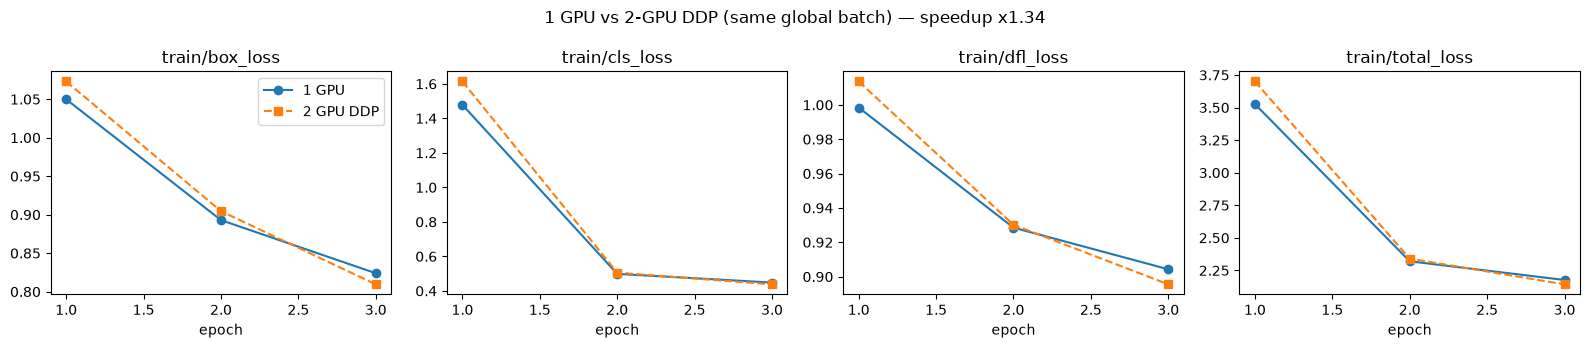

1 GPU                                                          \
      train/box_loss train/cls_loss train/dfl_loss train/total_loss     time   
epoch                                                                          
1             1.0499         1.4781         0.9984           3.5264   9.3722   
2             0.8929         0.4985         0.9285           2.3200  13.8130   
3             0.8240         0.4483         0.9043           2.1765  18.1709   

           2 GPU DDP                                                          
      train/box_loss train/cls_loss train/dfl_loss train/total_loss     time  
epoch                                                                         
1             1.0730         1.6136         1.0136           3.7002   7.0478  
2             0.9046         0.5056         0.9302           2.3403  10.3114  
3             0.8095         0.4379         0.8955           2.1429  13.5685

In [14]:
ddp = train_checks.ddp_vs_single(global_batch=16)
print(f"max relative difference of total train loss: {ddp['max_rel_loss_diff']:.1%}")
print(f"wall-clock: 1 GPU {ddp['time_1gpu_s']:.1f}s | DDP {ddp['time_ddp_s']:.1f}s "
      f"-> speedup x{ddp['speedup']:.2f}")
for label, run in ddp["runs"].items():
    print(f"{label:10s} per-GPU memory:", run_logging.grep_log(run, "epoch 3/")[0].split("gpu_mem_GB=")[1].split()[0], "GB")
train_checks.plot_ddp_vs_single(ddp)
ddp["table"].round(4)

### 7.2 Checkpointing + resume (DDP)
Start a 4-epoch DDP run, **kill the whole process group after 2 epochs** (simulated crash),
then resume from `weights/last.pt`. The interrupted `last.pt` must still hold the optimizer state,
and the resumed run must continue at epoch 3 so `results.csv` covers epochs 1–4 without gaps.
After a finished run both checkpoints are stripped to inference weights (`epoch=-1`, no optimizer).

In [15]:
res = train_checks.interrupt_and_resume(epochs=4, stop_after=2)
print("epochs after interruption:", res["epochs_before"])
print("epochs after resume      :", res["epochs_after"])
import pandas as pd
pd.DataFrame({f"{k} ({when})": v for when in ("before", "after") for k, v in res[when].items()}).T


### launch(): killing training after 2 epochs



epochs after interruption: [1, 2]
epochs after resume      : [1, 2, 3, 4]


,path,size_MB,epoch,best_fitness,has_optimizer,date
best (before),/home/mariusz_godlewski/car_recognition/runs/c...,26.66,1,0.6409,True,2026-10-24T15:13:40.195929+02:00
last (before),/home/mariusz_godlewski/car_recognition/runs/c...,26.66,1,0.6409,True,2026-10-24T15:13:40.195929+02:00
best (after),/home/mariusz_godlewski/car_recognition/runs/c...,5.57,-1,None,False,2026-10-24T15:13:55.551612+02:00
last (after),/home/mariusz_godlewski/car_recognition/runs/c...,5.57,-1,None,False,2026-10-24T15:13:55.551612+02:00


In [16]:
print("".join(l + "\n" for l in run_logging.grep_log(res["run_dir"], "# run")))

# run /home/mariusz_godlewski/car_recognition/runs/checks/resume_check started 2026-10-24 15:13:29
# run /home/mariusz_godlewski/car_recognition/runs/checks/resume_check started 2026-10-24 15:13:45 (resumed from epoch 2)



### 7.3 TensorBoard + hyperparameter logs
Read back the event files of the DDP run: per-epoch scalars and the HParams entry, plus the
`hparams.yaml` written next to them.

In [17]:
tb = train_checks.tensorboard_summary(ddp["runs"]["2 GPU DDP"])
print("HParams logged:", tb["hparams_logged"])
pd.Series(tb["scalars"], name="#points").to_frame()

HParams logged: True


,#points
train/box_loss,3
train/cls_loss,3
train/dfl_loss,3
lr/pg0,3
lr/pg1,3
lr/pg2,3
metrics/precision(B),4
metrics/recall(B),4
metrics/mAP50(B),4
metrics/mAP50-95(B),4


In [18]:
print((ddp["runs"]["2 GPU DDP"] / "hparams.yaml").read_text())

epochs: 3
patience: 20
batch: 16
imgsz: 1280
optimizer: AdamW
lr0: 0.002
lrf: 0.01
momentum: 0.937
weight_decay: 0.0005
warmup_epochs: 3.0
cos_lr: false
nbs: 64
amp: true
seed: 42
fraction: 0.5
single_cls: false
mosaic: 1.0
close_mosaic: 10
mixup: 0.0
copy_paste: 0.0
fliplr: 0.5
flipud: 0.0
degrees: 0.0
translate: 0.1
scale: 0.5
shear: 0.0
perspective: 0.0
hsv_h: 0.015
hsv_s: 0.7
hsv_v: 0.4
box: 7.5
cls: 0.5
dfl: 1.5
model: models/yolo11n.pt
data: /home/mariusz_godlewski/car_recognition/datasets/yolo/carpk.yaml
device: 0,1
workers: 8
world_size: 2
batch_per_gpu: 8
accumulate: 4
effective_batch: 64
lr0_effective: 0.002
save_dir: /home/mariusz_godlewski/car_recognition/runs/checks/ddp_2gpu



---
### Done (this part)

- **Environment**: GPU + CUDA confirmed, 2× RTX 4080 SUPER visible and free, all required
  packages present.
- **Data**: the combined CARPK + PUCPR+ devkit converted to YOLO format under
  `datasets/yolo/` with a clean train / val / test split and a ready-to-use `carpk.yaml`.
- **Model + loss**: COCO YOLO11n → 1-class, single `Detect` head; standard box + cls + DFL loss
  runs and back-propagates on real labels.
- **Multi-GPU**: DDP on both GPUs via `devices=0,1`; loss curves match a single-GPU run with the
  same global batch; single-GPU fallback `devices=0`.
- **Logging / hparams / checkpointing**: TensorBoard scalars + HParams, `train_log.txt`,
  `console.txt`, `hparams.yaml`; `best.pt` / `last.pt` every epoch, resume verified after a kill.
- **Sanity check**: one batch memorised (box + cls loss → ~0, mAP50 → ~1); logs in
  `runs/sanity/overfit_one_batch/`.

Next: the demo application (`app.py` / `predict.py`), then Phase 3 full training.